<a href="https://colab.research.google.com/github/risinukaviranga/ci-cd-build-failure-prediction/blob/main/Copy_of_CI_CD_Build_Failure_Prediction_Data_Pre_Processing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Install the required libraries

!pip install pandas numpy matplotlib seaborn scikit-learn

In [ ]:
# Import required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import sklearn

print("Environment setup successful!")

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Scikit-learn version:", sklearn.__version__)

Environment setup successful!
Pandas version: 2.2.3
NumPy version: 2.4.6
Scikit-learn version: 1.6.1


Giving the authorized acess to the google account


In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install -q duckdb pandas pyarrow scikit-learn


In [ ]:
import os
import duckdb
import pandas as pd
from pathlib import Path


In [ ]:
# Original dataset
CSV_PATH = (
    "/content/drive/MyDrive/CI-CD-Project/pipeline_data.csv"

)

# Folder for processed data
OUTPUT_DIR = (
    "/content/drive/MyDrive/CI-CD-Project/processed"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Temporary working directory on Colab's local disk
TEMP_DIR = "/content/duckdb_temp"

os.makedirs(TEMP_DIR, exist_ok=True)

# Check whether the original file exists
if not os.path.exists(CSV_PATH):
    raise FileNotFoundError(
        f"Dataset not found: {CSV_PATH}"
    )

file_size_gb = os.path.getsize(CSV_PATH) / (1024 ** 3)

print(f"Dataset found: {CSV_PATH}")
print(f"File size: {file_size_gb:.2f} GB")

Dataset found: /content/drive/MyDrive/CI-CD-Project/pipeline_data.csv
File size: 3.31 GB


In [ ]:
con = duckdb.connect()

# Use a conservative memory limit.
con.execute("SET memory_limit = '4GB'")

# Avoid excessive parallel disk activity.
con.execute("SET threads = 2")

# Put temporary query files on Colab's local disk.
con.execute(
    f"SET temp_directory = '{TEMP_DIR}'"
)

print("DuckDB is ready!")

DuckDB is ready!


In [ ]:
# Escape apostrophes in the file path
safe_path = CSV_PATH.replace("'", "''")

schema = con.execute(f"""
    DESCRIBE
    SELECT *
    FROM read_csv_auto(
        '{safe_path}',
        header = true,
        sample_size = 100000
    )
""").df()

display(schema)

print("Number of columns:", len(schema))

,column_name,column_type,null,key,default,extra
0,tr_build_id,BIGINT,YES,None,None,None
1,gh_project_name,VARCHAR,YES,None,None,None
2,gh_is_pr,BOOLEAN,YES,None,None,None
3,gh_pr_created_at,VARCHAR,YES,None,None,None
4,gh_pull_req_num,VARCHAR,YES,None,None,None
...,...,...,...,...,...,...
61,tr_log_buildduration,VARCHAR,YES,None,None,None
62,tr_original_commit,VARCHAR,YES,None,None,None
63,tr_duration,VARCHAR,YES,None,None,None
64,tr_status,VARCHAR,YES,None,None,None


Number of columns: 66


In [ ]:
sample = con.execute(f"""
    SELECT *
    FROM read_csv_auto(
        '{safe_path}',
        header = true,
        sample_size = 100000
    )
    LIMIT 10
""").df()

display(sample)

,tr_build_id,gh_project_name,gh_is_pr,gh_pr_created_at,gh_pull_req_num,gh_lang,git_merged_with,git_branch,gh_num_commits_in_push,gh_commits_in_push,...,tr_log_num_test_suites_run,tr_log_num_test_suites_ok,tr_log_num_test_suites_failed,tr_log_tests_failed,tr_log_testduration,tr_log_buildduration,tr_original_commit,tr_duration,tr_status,tr_jobs
0,3154,rspec/rspec-core,False,NA,NA,ruby,None,master,NA,NA,...,NA,NA,NA,None,114.83,NA,029e6972fcf719542deff1b2619d2945146e84da,956,passed,"[3161, 3163, 3160, 3162, 3164]"
1,3154,rspec/rspec-core,False,NA,NA,ruby,None,master,NA,NA,...,NA,NA,NA,None,171.37,NA,029e6972fcf719542deff1b2619d2945146e84da,956,passed,"[3161, 3163, 3160, 3162, 3164]"
2,3154,rspec/rspec-core,False,NA,NA,ruby,None,master,NA,NA,...,NA,NA,NA,None,177.02,NA,029e6972fcf719542deff1b2619d2945146e84da,956,passed,"[3161, 3163, 3160, 3162, 3164]"
3,3154,rspec/rspec-core,False,NA,NA,ruby,None,master,NA,NA,...,NA,NA,NA,None,182.05,NA,029e6972fcf719542deff1b2619d2945146e84da,956,passed,"[3161, 3163, 3160, 3162, 3164]"
4,3154,rspec/rspec-core,False,NA,NA,ruby,None,master,NA,NA,...,NA,NA,NA,None,113.26,NA,029e6972fcf719542deff1b2619d2945146e84da,956,passed,"[3161, 3163, 3160, 3162, 3164]"
5,3211,ruby-amqp/amqp,False,NA,NA,ruby,None,master,NA,NA,...,NA,NA,NA,None,31.61,NA,7fc267b949209b189fa76f232f7e88a9b938b363,391,passed,"[3214, 3215, 3212, 3216, 3213]"
6,3211,ruby-amqp/amqp,False,NA,NA,ruby,None,master,NA,NA,...,NA,NA,NA,None,31.04,NA,7fc267b949209b189fa76f232f7e88a9b938b363,391,passed,"[3214, 3215, 3212, 3216, 3213]"
7,3211,ruby-amqp/amqp,False,NA,NA,ruby,None,master,NA,NA,...,NA,NA,NA,None,31.15,NA,7fc267b949209b189fa76f232f7e88a9b938b363,391,passed,"[3214, 3215, 3212, 3216, 3213]"
8,3211,ruby-amqp/amqp,False,NA,NA,ruby,None,master,NA,NA,...,NA,NA,NA,None,30.92,NA,7fc267b949209b189fa76f232f7e88a9b938b363,391,passed,"[3214, 3215, 3212, 3216, 3213]"
9,3211,ruby-amqp/amqp,False,NA,NA,ruby,None,master,NA,NA,...,NA,NA,NA,None,34.6,NA,7fc267b949209b189fa76f232f7e88a9b938b363,391,passed,"[3214, 3215, 3212, 3216, 3213]"


In [ ]:
sample.to_csv(
    f"{OUTPUT_DIR}/dataset_sample.csv",
    index=False
)

Count number of records

In [ ]:
total_rows = con.execute(f"""
    SELECT COUNT(*)
    FROM read_csv_auto(
        '{safe_path}',
        header = true
    )
""").fetchone()[0]

print(f"Total records: {total_rows:,}")


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Total records: 3,881,992


ML problem is binary classification:


*   sucessfull build=0
*   fialed build=1



In [ ]:
print(schema[["column_name", "column_type"]].to_string(index=False))

                      column_name column_type
                      tr_build_id      BIGINT
                  gh_project_name     VARCHAR
                         gh_is_pr     BOOLEAN
                 gh_pr_created_at     VARCHAR
                  gh_pull_req_num     VARCHAR
                          gh_lang     VARCHAR
                  git_merged_with     VARCHAR
                       git_branch     VARCHAR
           gh_num_commits_in_push     VARCHAR
               gh_commits_in_push     VARCHAR
git_prev_commit_resolution_status     VARCHAR
            git_prev_built_commit     VARCHAR
                    tr_prev_build     VARCHAR
       gh_first_commit_created_at     VARCHAR
                     gh_team_size      BIGINT
            git_all_built_commits     VARCHAR
        git_num_all_built_commits      BIGINT
               git_trigger_commit     VARCHAR
           tr_virtual_merged_into     VARCHAR
            gh_num_issue_comments     VARCHAR
           gh_num_commit_comments 

Target column is "tr_status"

In [ ]:
TIMESTAMP_COLUMN = "tr_status"

the distribution of execution statuses (tr_status) across a massive dataset of over 3.8 million records

In [ ]:
TARGET_COLUMN = "tr_status"

# Safely quote a column identifier
target_sql = '"' + TARGET_COLUMN.replace('"', '""') + '"'

target_distribution = con.execute(f"""
    SELECT
        LOWER(TRIM(CAST({target_sql} AS VARCHAR))) AS status,
        COUNT(*) AS total
    FROM read_csv_auto(
        '{safe_path}',
        header = true,
        sample_size = 100000
    )
    GROUP BY 1
    ORDER BY total DESC
""").df()

display(target_distribution)

target_distribution.to_csv(
    f"{OUTPUT_DIR}/target_distribution.csv",
    index=False
)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,status,total
0,passed,2810783
1,failed,751531
2,errored,279483
3,canceled,40192
4,started,3


In [ ]:
TARGET_COLUMN = "tr_status"

TIMESTAMP_COLUMN = "gh_build_started_at"

FEATURE_COLUMNS = [
    "gh_is_pr",
    "gh_lang",
    "git_branch",
    "gh_num_commits_in_push",
    "gh_team_size",
    "git_diff_src_churn",
    "git_diff_test_churn",
    "gh_diff_files_added",
    "gh_diff_files_deleted",
    "gh_diff_files_modified",
    "gh_diff_tests_added",
    "gh_diff_tests_deleted",
    "gh_diff_src_files",
    "gh_diff_doc_files",
    "gh_diff_other_files",
    "gh_num_commits_on_files_touched",
    "gh_sloc",
    "gh_test_lines_per_kloc",
    "gh_test_cases_per_kloc",
    "gh_asserts_cases_per_kloc",
    "gh_by_core_team_member",
    "gh_description_complexity",
    "gh_repo_age",
    "gh_repo_num_commits"
]

configure the actual features-that are genuinely available before execution

In [ ]:
TARGET_COLUMN = "tr_status"

TIMESTAMP_COLUMN = "gh_build_started_at"

FEATURE_COLUMNS = [
    "gh_is_pr",
    "gh_lang",
    "git_branch",
    "gh_num_commits_in_push",
    "gh_team_size",
    "git_diff_src_churn",
    "git_diff_test_churn",
    "gh_diff_files_added",
    "gh_diff_files_deleted",
    "gh_diff_files_modified",
    "gh_diff_tests_added",
    "gh_diff_tests_deleted",
    "gh_diff_src_files",
    "gh_diff_doc_files",
    "gh_diff_other_files",
    "gh_num_commits_on_files_touched",
    "gh_sloc",
    "gh_test_lines_per_kloc",
    "gh_test_cases_per_kloc",
    "gh_asserts_cases_per_kloc",
    "gh_by_core_team_member",
    "gh_description_complexity",
    "gh_repo_age",
    "gh_repo_num_commits"
]

Map the actual build statuses

In [ ]:
SUCCESS_VALUES = [
    "success",
    "passed"
]

FAILURE_VALUES = [
    "failure",
    "failed"
]

Create the cleaned Parquet dataset
Selects your configured feature columns.



Converts the status into a binary target.



Excludes unknown statuses.



Excludes records with invalid timestamps.



Preserves feature missing values for later imputation.



Writes the cleaned data to compressed Parquet.
---



In [ ]:
def quote_identifier(name):
    return '"' + name.replace('"', '""') + '"'

def sql_string(value):
    return "'" + value.replace("'", "''") + "'"

# Validate configuration
if not FEATURE_COLUMNS:
    raise ValueError("Add your real feature columns first.")

if TARGET_COLUMN in FEATURE_COLUMNS:
    raise ValueError("Target column cannot be a feature.")

if TIMESTAMP_COLUMN in FEATURE_COLUMNS:
    raise ValueError("Timestamp is for splitting, not a feature.")

if len(FEATURE_COLUMNS) != len(set(FEATURE_COLUMNS)):
    raise ValueError("Duplicate feature columns found.")

# Confirm all requested columns exist
available_columns = set(schema["column_name"])

required_columns = (
    set(FEATURE_COLUMNS)
    | {TARGET_COLUMN, TIMESTAMP_COLUMN}
)

missing_columns = required_columns - available_columns

if missing_columns:
    raise ValueError(
        f"Columns not found in CSV: {missing_columns}"
    )

# Build safe SQL expressions
feature_sql = [
    quote_identifier(col)
    for col in FEATURE_COLUMNS
]

target_sql = quote_identifier(TARGET_COLUMN)
timestamp_sql = quote_identifier(TIMESTAMP_COLUMN)

success_sql = ", ".join(
    sql_string(x.lower()) for x in SUCCESS_VALUES
)

failure_sql = ", ".join(
    sql_string(x.lower()) for x in FAILURE_VALUES
)

clean_file = f"{OUTPUT_DIR}/cleaned_dataset.parquet"

# Build cleaned dataset
clean_query = f"""
    SELECT
        {", ".join(feature_sql)},

        TRY_CAST(
            {timestamp_sql} AS TIMESTAMP
        ) AS event_time,

        CASE
            WHEN LOWER(TRIM(CAST({target_sql} AS VARCHAR)))
                IN ({success_sql})
                THEN 0

            WHEN LOWER(TRIM(CAST({target_sql} AS VARCHAR)))
                IN ({failure_sql})
                THEN 1

            ELSE NULL
        END AS label

    FROM read_csv_auto(
        '{safe_path}',
        header = true,
        sample_size = 100000,
        ignore_errors = false
    )
"""

# Export only records with valid labels and timestamps
clean_path_sql = clean_file.replace("'", "''")

con.execute(f"""
    COPY (
        SELECT *
        FROM ({clean_query}) AS source
        WHERE label IS NOT NULL
          AND event_time IS NOT NULL
    )
    TO '{clean_path_sql}'
    (FORMAT PARQUET, COMPRESSION ZSTD)
""")

print("Cleaned dataset created!")
print(clean_file)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Cleaned dataset created!
/content/drive/MyDrive/CI-CD-Project/processed/cleaned_dataset.parquet


check the clean dataset


In [ ]:
clean_path_sql = clean_file.replace("'", "''")

clean_summary = con.execute(f"""
    SELECT
        COUNT(*) AS total_records,

        COUNT(*) FILTER (
            WHERE label = 0
        ) AS successful_builds,

        COUNT(*) FILTER (
            WHERE label = 1
        ) AS failed_builds,

        COUNT(*) FILTER (
            WHERE event_time IS NULL
        ) AS missing_timestamps

    FROM read_parquet('{clean_path_sql}')
""").df()

display(clean_summary)

,total_records,successful_builds,failed_builds,missing_timestamps
0,3562314,2810783,751531,0


check the class distribution

In [ ]:
class_distribution = con.execute(f"""
    SELECT
        label,
        COUNT(*) AS total,
        ROUND(
            100.0 * COUNT(*) /
            SUM(COUNT(*)) OVER (),
            2
        ) AS percentage
    FROM read_parquet('{clean_path_sql}')
    GROUP BY label
    ORDER BY label
""").df()

display(class_distribution)

,label,total,percentage
0,0,2810783,78.9
1,1,751531,21.1


Split the dataset chronologically

70% oldest records: Training



15% next records: Validation



15% newest records: Testing

create tarin,validation and test parquet files

In [ ]:
# Find chronological cutoffs
cutoffs = con.execute(f"""
    SELECT
        quantile_disc(event_time, 0.70) AS train_cutoff,
        quantile_disc(event_time, 0.85) AS validation_cutoff
    FROM read_parquet('{clean_path_sql}')
""").fetchone()

train_cutoff, validation_cutoff = cutoffs

print("Training cutoff:", train_cutoff)
print("Validation cutoff:", validation_cutoff)

Training cutoff: 2015-12-15 13:35:28
Validation cutoff: 2016-04-16 02:41:13


In [ ]:
train_file = f"{OUTPUT_DIR}/train.parquet"
validation_file = f"{OUTPUT_DIR}/validation.parquet"
test_file = f"{OUTPUT_DIR}/test.parquet"

def export_parquet(query, output_file):
    output_sql = output_file.replace("'", "''")

    con.execute(f"""
        COPY ({query})
        TO '{output_sql}'
        (FORMAT PARQUET, COMPRESSION ZSTD)
    """)

# Training: oldest records
export_parquet(
    f"""
    SELECT *
    FROM read_parquet('{clean_path_sql}')
    WHERE event_time <= TIMESTAMP '{train_cutoff}'
    """,
    train_file
)

# Validation: records after training cutoff
# and up to validation cutoff
export_parquet(
    f"""
    SELECT *
    FROM read_parquet('{clean_path_sql}')
    WHERE event_time > TIMESTAMP '{train_cutoff}'
      AND event_time <= TIMESTAMP '{validation_cutoff}'
    """,
    validation_file
)

# Testing: newest records
export_parquet(
    f"""
    SELECT *
    FROM read_parquet('{clean_path_sql}')
    WHERE event_time > TIMESTAMP '{validation_cutoff}'
    """,
    test_file
)

print("Chronological split completed!")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Chronological split completed!


In [ ]:
files = {
    "Training": train_file,
    "Validation": validation_file,
    "Testing": test_file
}

for name, file_path in files.items():

    path = file_path.replace("'", "''")

    result = con.execute(f"""
        SELECT
            COUNT(*) AS total_records,

            COUNT(*) FILTER (
                WHERE label = 0
            ) AS success_count,

            COUNT(*) FILTER (
                WHERE label = 1
            ) AS failure_count,

            MIN(event_time) AS first_timestamp,
            MAX(event_time) AS last_timestamp

        FROM read_parquet('{path}')
    """).df()

    print(f"\n========== {name.upper()} ==========")
    display(result)


========== TRAINING ==========


,total_records,success_count,failure_count,first_timestamp,last_timestamp
0,2493621,1953301,540320,2011-04-16 11:24:39,2015-12-15 13:35:28



========== VALIDATION ==========


,total_records,success_count,failure_count,first_timestamp,last_timestamp
0,534349,430084,104265,2015-12-15 13:40:43,2016-04-16 02:41:13



========== TESTING ==========


,total_records,success_count,failure_count,first_timestamp,last_timestamp
0,534344,427398,106946,2016-04-16 02:42:55,2016-08-31 23:59:27


Export reports for review

In [ ]:
# Save the final processing summary
summary = []

for name, file_path in files.items():

    path = file_path.replace("'", "''")

    row = con.execute(f"""
        SELECT
            COUNT(*) AS total_records,
            COUNT(*) FILTER (WHERE label = 0) AS successes,
            COUNT(*) FILTER (WHERE label = 1) AS failures,
            MIN(event_time) AS first_date,
            MAX(event_time) AS last_date
        FROM read_parquet('{path}')
    """).fetchone()

    summary.append({
        "dataset": name,
        "total_records": row[0],
        "successes": row[1],
        "failures": row[2],
        "first_date": row[3],
        "last_date": row[4]
    })

summary_df = pd.DataFrame(summary)

display(summary_df)

summary_df.to_csv(
    f"{OUTPUT_DIR}/processing_summary.csv",
    index=False
)

,dataset,total_records,successes,failures,first_date,last_date
0,Training,2493621,1953301,540320,2011-04-16 11:24:39,2015-12-15 13:35:28
1,Validation,534349,430084,104265,2015-12-15 13:40:43,2016-04-16 02:41:13
2,Testing,534344,427398,106946,2016-04-16 02:42:55,2016-08-31 23:59:27


Checking missing values from records

In [ ]:
missing_query = f"""
    SELECT
        COUNT(*) AS total_records
    FROM read_csv_auto(
        '{safe_path}',
        header = true
    )
"""

total_records = con.execute(
    missing_query
).fetchone()[0]

missing_counts = []

for column in schema["column_name"]:

    quoted = '"' + column.replace('"', '""') + '"'

    count = con.execute(f"""
        SELECT COUNT(*)
        FROM read_csv_auto(
            '{safe_path}',
            header = true
        )
        WHERE {quoted} IS NULL
    """).fetchone()[0]

    missing_counts.append({
        "column": column,
        "missing_count": count,
        "missing_percentage": round(
            count / total_records * 100, 2
        )
    })

missing_df = pd.DataFrame(missing_counts)

display(
    missing_df.sort_values(
        "missing_percentage",
        ascending=False
    )
)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

... (58 outputs left out)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,column,missing_count,missing_percentage
59,tr_log_tests_failed,3724807,95.95
6,git_merged_with,3061250,78.86
18,tr_virtual_merged_into,3061250,78.86
49,tr_log_frameworks,1542320,39.73
51,tr_log_bool_tests_failed,1474485,37.98
...,...,...,...
61,tr_log_buildduration,0,0.00
62,tr_original_commit,0,0.00
63,tr_duration,0,0.00
64,tr_status,0,0.00


saves the details of missing values


In [ ]:
missing_df.to_csv(
    f"{OUTPUT_DIR}/missing_values.csv",
    index=False
)

Duplicate analysis

check build IDs

In [ ]:
duplicate_result = con.execute(f"""
    SELECT
        COUNT(*) AS total_records,
        COUNT(DISTINCT tr_build_id) AS unique_build_ids,
        COUNT(*) - COUNT(DISTINCT tr_build_id)
            AS duplicate_id_count
    FROM read_csv_auto(
        '{safe_path}',
        header = true
    )
""").df()

display(duplicate_result)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,total_records,unique_build_ids,duplicate_id_count
0,3881992,925897,2956095


Inspect duplicate IDs

In [ ]:
duplicate_ids = con.execute(f"""
    SELECT
        tr_build_id,
        COUNT(*) AS occurrences
    FROM read_csv_auto(
        '{safe_path}',
        header = true
    )
    GROUP BY tr_build_id
    HAVING COUNT(*) > 1
    ORDER BY occurrences DESC
    LIMIT 20
""").df()

display(duplicate_ids)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,tr_build_id,occurrences
0,97699584,690
1,67453124,252
2,67452801,252
3,67453782,168
4,67567287,168
5,67453960,168
6,102117973,165
7,102174365,165
8,101460598,165
9,144768906,165


In [ ]:
TARGET_COLUMN = "tr_status"

In [ ]:
target_distribution = con.execute(f"""
    SELECT
        LOWER(TRIM(tr_status)) AS status,
        COUNT(*) AS total_records
    FROM read_csv_auto(
        '{safe_path}',
        header = true
    )
    GROUP BY 1
    ORDER BY total_records DESC
""").df()

display(target_distribution)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,status,total_records
0,passed,2810783
1,failed,751531
2,errored,279483
3,canceled,40192
4,started,3


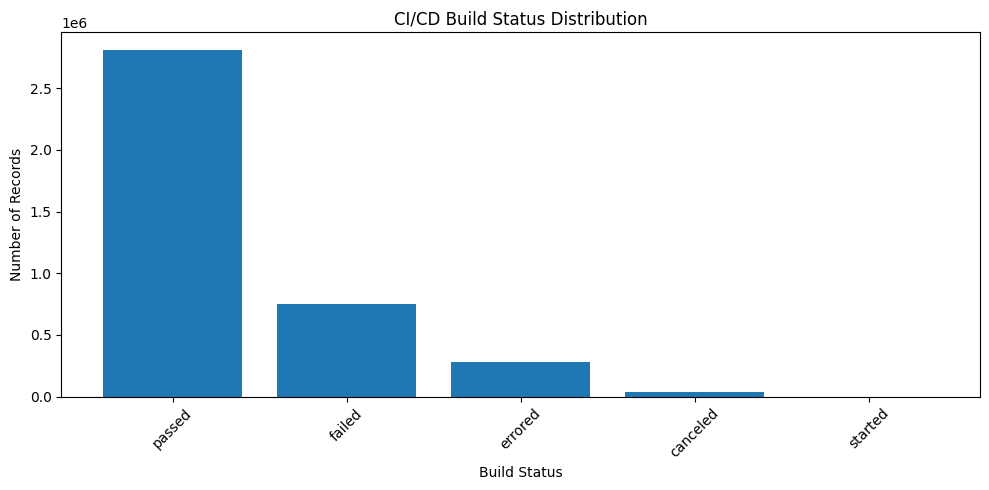

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    target_distribution["status"].fillna("NULL"),
    target_distribution["total_records"]
)

plt.title("CI/CD Build Status Distribution")
plt.xlabel("Build Status")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

this dataset is imbalance


Uderstanding the data leakage:
Data leakage happens when the model receives information that would not be available when making a real prediction.

In [1]:
LEAKAGE_CANDIDATES = [
    "tr_log_bool_tests_failed",
    "tr_log_num_tests_failed",
    "tr_log_num_tests_ok",
    "tr_log_num_tests_run",
    "tr_log_testduration",
    "tr_log_buildduration",
    "tr_duration",
    "tr_status",
    "tr_log_status"
]